In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
%matplotlib inline
plt.rcParams["font.family"] = "Arial"
from matplotlib.lines import Line2D

from scipy.stats import pearsonr, spearmanr

from additives_microbiota.constants import MIXTURES, ADDITIVE_VARS
from additives_microbiota.plotting import process_string, process_string_pretty_vars
from additives_microbiota.mb_utils import (taxonomy_dict, prevalence, dict_ASV_names, taxonID_shortName, compute_log_ratios_using_significant_features, birdman_plot_single_var)

In [2]:
ADDITIVE_VARS = [v for v in ADDITIVE_VARS if v != "other_additives"]

In [3]:
run_suffix = "adjustedBatch"  # "unadjusted"  # "adjustedMany"

slurm_outputs_dir = f"./slurm_outputs/{run_suffix}"

### Loading Metadata and Counts Data

In [4]:
meta = pd.read_csv(
    f"../../data/metadata_files/meta_log_ratios_{run_suffix}.csv", index_col=0
)

## Plotting Log Ratio Correlation Clustermap

In [5]:
def plot_LR_correlation_clustermap(
    lr,
    additive_lr_vars,
    diversity_vars,
    extra_vars,
    additive_vars,
    ignore_vars=[],
    figsize=(15, 15),
    color_range=(-0.6, 0.6),
):
    """
    Plot a correlation clustermap showing relationships between additives, diversity metrics and other variables.

    Parameters
    ----------
    lr : pandas.DataFrame
        Input dataframe containing all variables
    additive_lr_vars : list
        List of log ratio additive variable names
    diversity_vars : list
        List of diversity metric variable names
    extra_vars : list
        List of additional variables to include
    additive_vars : list
        List of raw additive variable names

    Returns
    -------
    g : seaborn.ClusterGrid
        The clustermap plot object
    """
    # Combine variables in desired order
    all_vars = additive_lr_vars + diversity_vars + extra_vars + additive_vars
    all_vars = [i for i in all_vars if i not in ignore_vars]

    # Calculate correlation matrix
    corr_matrix = lr[all_vars].corr(method="pearson")
    corr_matrix.index = [process_string_pretty_vars(i) for i in corr_matrix.index]
    corr_matrix.columns = [process_string_pretty_vars(i) for i in corr_matrix.columns]

    # Create diagonal mask
    mask = np.eye(len(corr_matrix), dtype=bool)

    # Plot clustermap
    g = sns.clustermap(
        corr_matrix,
        figsize=figsize,
        annot=True,
        cmap="PiYG",
        fmt=".2f",
        row_cluster=False,
        col_cluster=False,
        vmin=color_range[0],
        vmax=color_range[1],
        center=0,
        mask=mask,
        dendrogram_ratio=0.1,
        cbar_pos=(0.1, 0.95, 0.7, 0.015),
        cbar_kws={"orientation": "horizontal", "label": "Pearson Correlation"},
        linewidths=1,
    )
    g.ax_heatmap.set_xlabel("")
    g.ax_heatmap.set_ylabel("")

    ax = g.ax_heatmap

    # Define group boundaries and labels
    group_info = {
        "Log ratios (Additives)": (0, len(additive_lr_vars) - 1),
        "Gut Diversities": (
            len(additive_lr_vars),
            len(additive_lr_vars) + len(diversity_vars) - 1,
        ),
        "Others": (
            len(additive_lr_vars) + len(diversity_vars),
            len(additive_lr_vars) + len(diversity_vars) + len(extra_vars) - 1,
        ),
        "Additives": (
            len(additive_lr_vars) + len(diversity_vars) + len(extra_vars),
            len(all_vars) - 1,
        ),
    }

    # Add group brackets and labels
    for label, (start_idx, end_idx) in group_info.items():
        start_center = start_idx + 0.5
        end_center = end_idx + 0.5

        ax.annotate(
            "",
            xy=(-0.5, start_center),
            xytext=(-0.5, end_center),
            arrowprops=dict(arrowstyle="<->", lw=2, color="black"),
            annotation_clip=False,
            transform=ax.transData,
        )

        ax.text(
            -0.8,
            (start_center + end_center) / 2,
            label,
            ha="right",
            va="center",
            rotation=90,
            transform=ax.transData,
        )

    # Add group separator lines
    boundaries = [
        len(additive_lr_vars),
        len(additive_lr_vars) + len(diversity_vars),
        len(additive_lr_vars) + len(diversity_vars) + len(extra_vars),
    ]

    x_min, x_max = ax.get_xlim()
    for boundary in boundaries:
        ax.hlines(boundary, x_min, x_max, colors="black", lw=2)

    plt.setp(
        g.ax_heatmap.get_xticklabels(), rotation=60, ha="right", rotation_mode="anchor"
    )
    return g

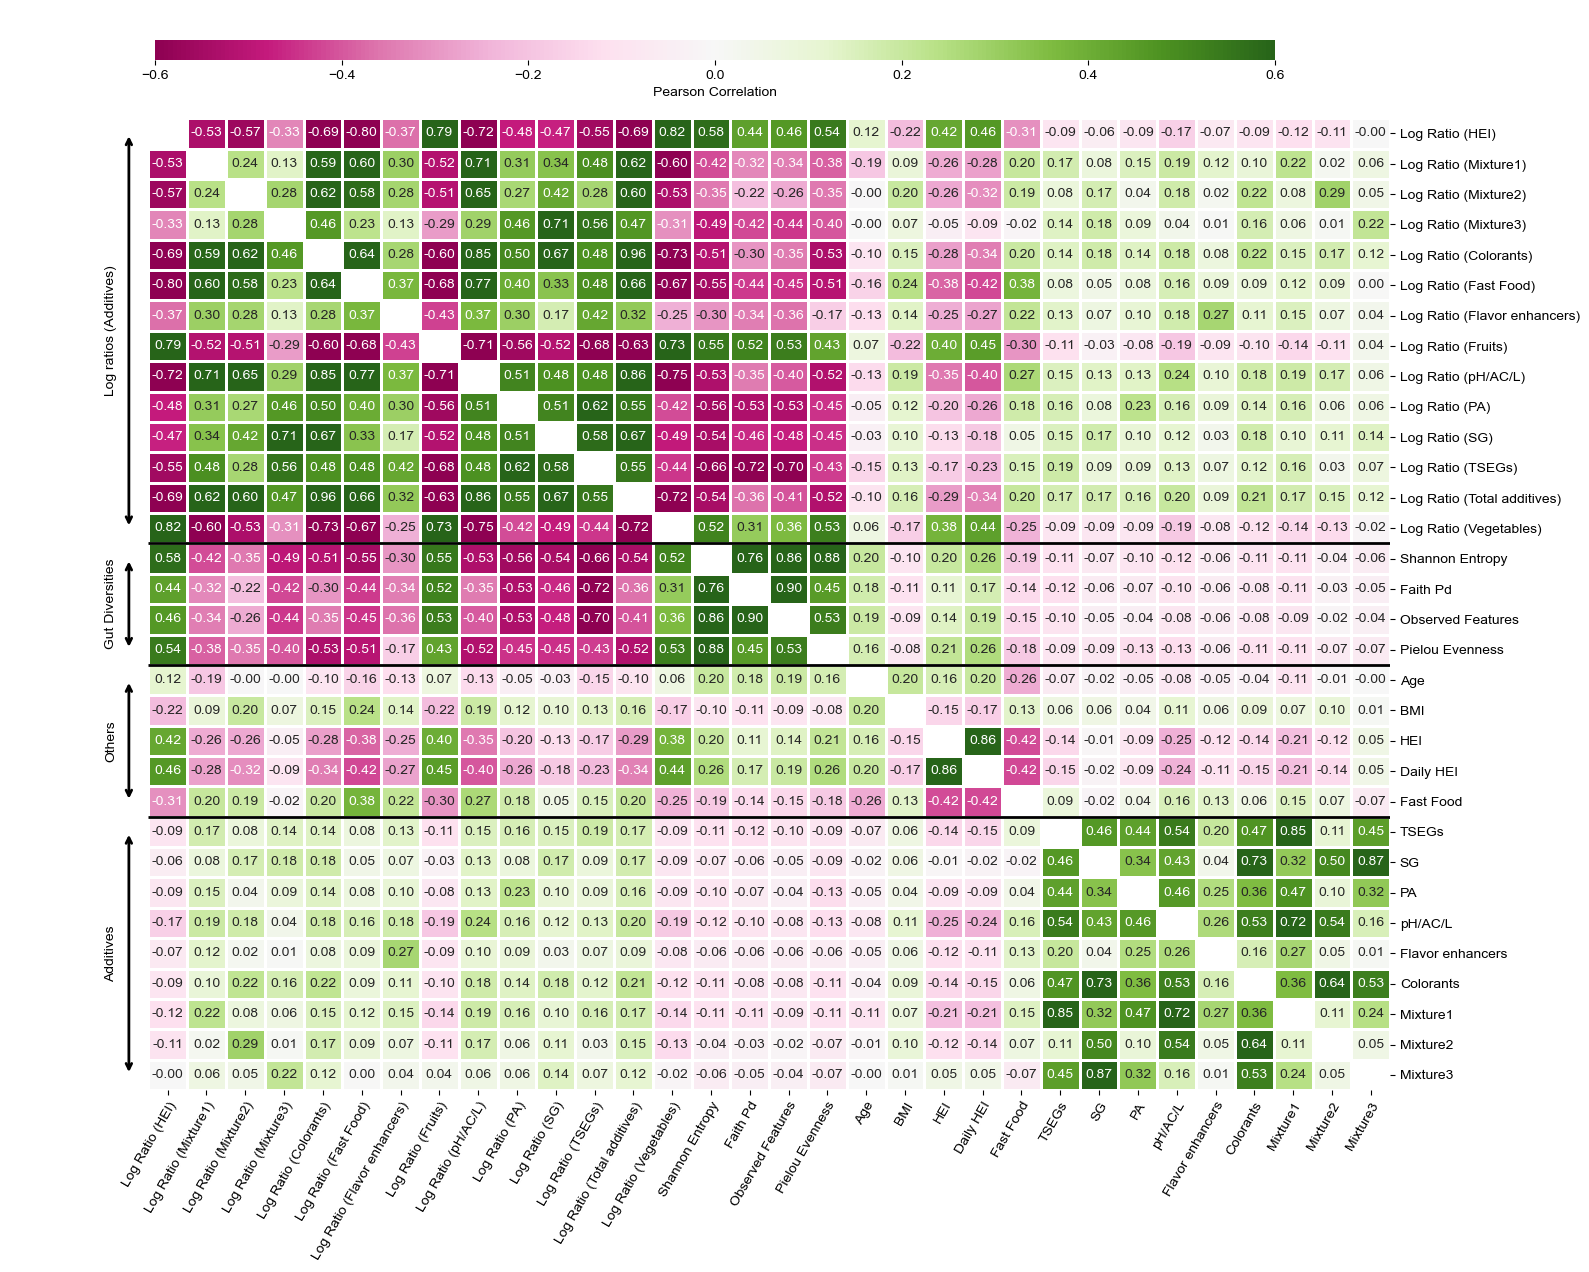

In [6]:
extra_vars = ["age", "bmi", "HEI", "daily_HEI", "fast_food_fg_eaten"]

additive_lr_vars = [i for i in meta.columns if "LR_" in i and "minus" not in i]

diversity_vars = [
    "shannon_entropy",
    "faith_pd",
    "observed_features",
    "pielou_evenness",
]


# Combine variables in the desired order
all_vars = additive_lr_vars + diversity_vars + extra_vars + ADDITIVE_VARS + MIXTURES
ignore_vars = [i for i in all_vars if "HEI" in i and "LR" not in i and "minus" in i]

plot_LR_correlation_clustermap(
    meta,
    additive_lr_vars=additive_lr_vars,
    diversity_vars=diversity_vars,
    extra_vars=extra_vars,
    additive_vars=ADDITIVE_VARS + MIXTURES,
    ignore_vars=ignore_vars,
    figsize=(16, 13),
)

plt.savefig(
    f"../figures/birdman/additive_correlation_clustermap_{run_suffix}.png",
    dpi=300,
    bbox_inches="tight",
)

In [7]:
# def plot_LR_correlation_clustermap_mini(
#     lr,
#     additive_lr_vars,
#     diversity_vars,
#     extra_vars,
#     additive_vars,
#     xaxis_vars=None,
#     ignore_vars=[],
#     figsize=(15, 15),
#     color_range=(-0.6, 0.6),
#     cbar_pos=(0.1, 0.95, 0.7, 0.015),
# ):
#     """
#     Plot a correlation clustermap showing relationships between additives, diversity metrics and other variables.

#     Parameters
#     ----------
#     lr : pandas.DataFrame
#         Input dataframe containing all variables
#     additive_lr_vars : list
#         List of log ratio additive variable names
#     diversity_vars : list
#         List of diversity metric variable names
#     extra_vars : list
#         List of additional variables to include
#     additive_vars : list
#         List of raw additive variable names
#     xaxis_vars : list or None
#         If provided, only these variables (after processing) will appear on the x-axis
#     ignore_vars : list
#         Variables to drop from the full list
#     figsize : tuple
#         Figure size
#     color_range : tuple
#         (vmin, vmax) for heatmap colormap

#     Returns
#     -------
#     g : seaborn.ClusterGrid
#         The clustermap plot object
#     """
#     # Combine variables in desired order, then drop ignored
#     all_vars = additive_lr_vars + diversity_vars + extra_vars + additive_vars
#     all_vars = [v for v in all_vars if v not in ignore_vars]

#     # Calculate correlation matrix once
#     corr_matrix = lr[all_vars].corr(method="pearson")
#     corr_matrix.index = [process_string_pretty_vars(i) for i in corr_matrix.index]
#     corr_matrix.columns = [process_string_pretty_vars(i) for i in corr_matrix.columns]

#     # If user supplied xaxis_vars, subset columns only
#     if xaxis_vars is not None:
#         xaxis_proc = [process_string_pretty_vars(i) for i in xaxis_vars]
#         corr_matrix = corr_matrix.loc[:, xaxis_proc]

#     # Create mask matching the (possibly non-square) matrix
#     mask = np.zeros_like(corr_matrix, dtype=bool)

#     # Plot clustermap
#     g = sns.clustermap(
#         corr_matrix,
#         figsize=figsize,
#         annot=True,
#         cmap="PiYG",
#         fmt=".2f",
#         row_cluster=False,
#         col_cluster=False,
#         vmin=color_range[0],
#         vmax=color_range[1],
#         center=0,
#         mask=mask,
#         dendrogram_ratio=0.1,
#         cbar_pos=cbar_pos,
#         cbar_kws={"orientation": "horizontal", "label": "Pearson Correlation"},
#         linewidths=1,
#     )
#     g.ax_heatmap.set_xlabel("")
#     g.ax_heatmap.set_ylabel("")

#     ax = g.ax_heatmap

#     # Define group boundaries and labels
#     group_info = {
#         "Log ratios (Additives)": (0, len(additive_lr_vars) - 1),
#         "Gut Diversities": (
#             len(additive_lr_vars),
#             len(additive_lr_vars) + len(diversity_vars) - 1,
#         ),
#         "Others": (
#             len(additive_lr_vars) + len(diversity_vars),
#             len(additive_lr_vars) + len(diversity_vars) + len(extra_vars) - 1,
#         ),
#         "Additives": (
#             len(additive_lr_vars) + len(diversity_vars) + len(extra_vars),
#             len(all_vars) - 1,
#         ),
#     }

#     # Add group brackets and labels
#     for label, (start_idx, end_idx) in group_info.items():
#         start_center = start_idx + 0.5
#         end_center = end_idx + 0.5

#         ax.annotate(
#             "",
#             xy=(-0.5, start_center),
#             xytext=(-0.5, end_center),
#             arrowprops=dict(arrowstyle="<->", lw=2, color="black"),
#             annotation_clip=False,
#             transform=ax.transData,
#         )

#         ax.text(
#             -0.8,
#             (start_center + end_center) / 2,
#             label,
#             ha="right",
#             va="center",
#             rotation=90,
#             transform=ax.transData,
#         )

#     # Add group separator lines
#     boundaries = [
#         len(additive_lr_vars),
#         len(additive_lr_vars) + len(diversity_vars),
#         len(additive_lr_vars) + len(diversity_vars) + len(extra_vars),
#     ]
#     x_min, x_max = ax.get_xlim()
#     for boundary in boundaries:
#         ax.hlines(boundary, x_min, x_max, colors="black", lw=2)

#     return g

In [11]:
def pearson_corr_and_pvalues(df):
    """
    Compute Pearson correlation matrix and corresponding two-sided p-value matrix
    using pairwise complete observations.

    Returns
    -------
    corr : pandas.DataFrame
    pvals : pandas.DataFrame
    """
    cols = list(df.columns)
    corr = df.corr(method="pearson")

    pvals = corr.copy()
    pvals.loc[:, :] = 1.0

    for i, c1 in enumerate(cols):
        for j, c2 in enumerate(cols):
            if j < i:
                continue
            x = df[c1]
            y = df[c2]
            ok = x.notna() & y.notna()
            n = int(ok.sum())
            if n < 3:
                r = float("nan")
                p = float("nan")
            else:
                r, p = pearsonr(x[ok].to_numpy(), y[ok].to_numpy())

            corr.loc[c1, c2] = r
            corr.loc[c2, c1] = r
            pvals.loc[c1, c2] = p
            pvals.loc[c2, c1] = p

    return corr, pvals


def pvalue_to_stars(p, thresholds=(0.05, 0.01, 0.001)):
    if p is None or (isinstance(p, float) and np.isnan(p)):
        return ""
    if p < thresholds[2]:
        return "***"
    if p < thresholds[1]:
        return "**"
    if p < thresholds[0]:
        return "*"
    return ""


def plot_LR_correlation_clustermap_mini(
    lr,
    additive_lr_vars,
    diversity_vars,
    extra_vars,
    additive_vars,
    xaxis_vars=None,
    ignore_vars=[],
    figsize=(15, 15),
    color_range=(-0.6, 0.6),
    cbar_pos=(0.1, 0.95, 0.7, 0.015),
    cell_value_type="corr",  # "corr" or "p-star"
    star_thresholds=(0.05, 0.01, 0.001),
):
    """
    Plot a correlation clustermap showing relationships between additives, diversity metrics and other variables.

    cell_value_type
        "corr": annotate with correlation values
        "p-star": annotate with significance stars based on p-values (*, **, ***)

    Notes
    -----
    Gut diversity variables (diversity_vars) are removed from the rows (y axis) rendering.
    They can still appear on the x axis if included via xaxis_vars (or if xaxis_vars is None).
    """
    all_vars = additive_lr_vars + diversity_vars + extra_vars + additive_vars
    all_vars = [v for v in all_vars if v not in ignore_vars]

    base_df = lr[all_vars]

    corr_matrix, pval_matrix = pearson_corr_and_pvalues(base_df)

    corr_matrix.index = [process_string_pretty_vars(i) for i in corr_matrix.index]
    corr_matrix.columns = [process_string_pretty_vars(i) for i in corr_matrix.columns]
    pval_matrix.index = [process_string_pretty_vars(i) for i in pval_matrix.index]
    pval_matrix.columns = [process_string_pretty_vars(i) for i in pval_matrix.columns]

    if xaxis_vars is not None:
        xaxis_proc = [process_string_pretty_vars(i) for i in xaxis_vars]
        corr_matrix = corr_matrix.loc[:, xaxis_proc]
        pval_matrix = pval_matrix.loc[:, xaxis_proc]

    # remove gut diversity variables from rows (y axis) only
    y_keep = [
        process_string_pretty_vars(v)
        for v in (additive_lr_vars + extra_vars + additive_vars)
        if v not in ignore_vars
    ]
    corr_matrix = corr_matrix.loc[y_keep, :]
    pval_matrix = pval_matrix.loc[y_keep, :]

    mask = np.zeros_like(corr_matrix, dtype=bool)

    if cell_value_type == "p-star":
        annot_matrix = pval_matrix.map(
            lambda p: pvalue_to_stars(p, thresholds=star_thresholds)
        )
        annot_arg = annot_matrix.values
        fmt = ""
        annot_kws = {"fontsize": 14, "fontweight": "bold"}
    else:
        annot_arg = True
        fmt = ".2f"
        annot_kws = None

    g = sns.clustermap(
        corr_matrix,
        figsize=figsize,
        annot=annot_arg,
        annot_kws=annot_kws,
        cmap="PiYG",
        fmt=fmt,
        row_cluster=False,
        col_cluster=False,
        vmin=color_range[0],
        vmax=color_range[1],
        center=0,
        mask=mask,
        dendrogram_ratio=0.1,
        cbar_pos=cbar_pos,
        cbar_kws={"orientation": "horizontal", "label": "Pearson Correlation"},
        linewidths=1,
    )

    if cell_value_type == "p-star":
        for txt in g.ax_heatmap.texts:
            txt.set_ha("center")
            txt.set_va("top")

    g.ax_heatmap.set_xlabel("")
    g.ax_heatmap.set_ylabel("")

    ax = g.ax_heatmap

    group_info = {
        "Log ratios": (0, len(additive_lr_vars) - 1),
        "Host & Diet": (
            len(additive_lr_vars),
            len(additive_lr_vars) + len(extra_vars) - 1,
        ),
        "Additives": (
            len(additive_lr_vars) + len(extra_vars),
            len(y_keep) - 1,
        ),
    }

    for label, (start_idx, end_idx) in group_info.items():
        start_center = start_idx + 0.5
        end_center = end_idx + 0.5

        ax.annotate(
            "",
            xy=(-0.5, start_center),
            xytext=(-0.5, end_center),
            arrowprops=dict(arrowstyle="<->", lw=2, color="black"),
            annotation_clip=False,
            transform=ax.transData,
        )

        ax.text(
            -0.6,
            (start_center + end_center) / 2,
            label,
            ha="right",
            va="center",
            rotation=90,
            transform=ax.transData,
        )

    boundaries = [
        len(additive_lr_vars),
        len(additive_lr_vars) + len(extra_vars),
    ]
    x_min, x_max = ax.get_xlim()
    for boundary in boundaries:
        ax.hlines(boundary, x_min, x_max, colors="black", lw=2)

    plt.setp(
        g.ax_heatmap.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor"
    )
    return g, corr_matrix

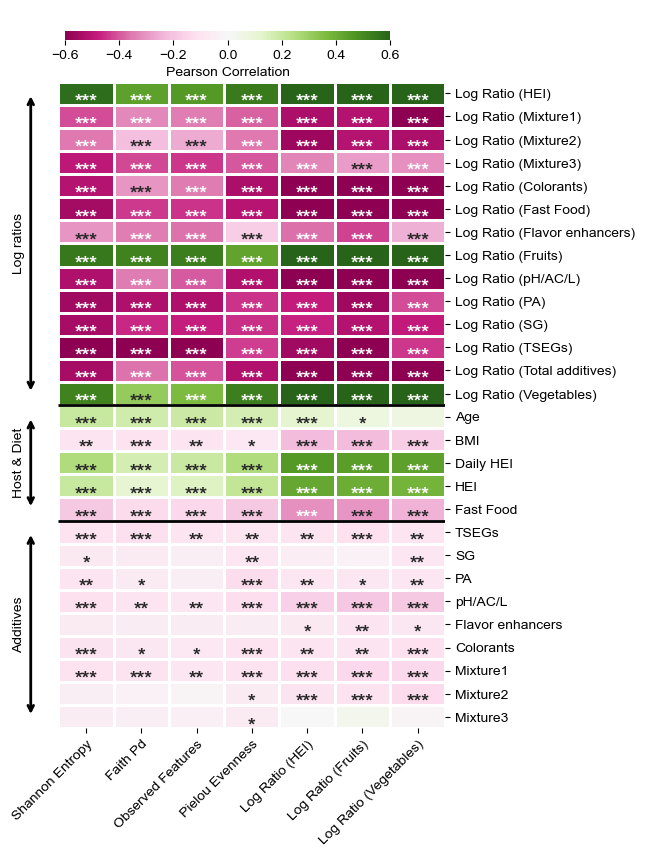

In [12]:
extra_vars = ["age", "bmi", "daily_HEI", "HEI", "fast_food_fg_eaten"]

additive_lr_vars = [i for i in meta.columns if "LR_" in i and "minus" not in i]

diversity_vars = [
    "shannon_entropy",
    "faith_pd",
    "observed_features",
    "pielou_evenness",
]


xaxis_vars = diversity_vars + ["LR_HEI", "LR_fruits_fg_eaten", "LR_vegetables_fg_eaten"]

# Combine variables in the desired order
all_vars = additive_lr_vars + diversity_vars + extra_vars + ADDITIVE_VARS + MIXTURES
ignore_vars = [i for i in all_vars if "HEI" in i and "LR" not in i and "minus" in i]

g, corr_matrix = plot_LR_correlation_clustermap_mini(
    meta,
    additive_lr_vars=additive_lr_vars,
    diversity_vars=diversity_vars,
    extra_vars=extra_vars,
    additive_vars=ADDITIVE_VARS + MIXTURES,
    ignore_vars=ignore_vars,
    cell_value_type="p-star",
    figsize=(6.5, 9),
    xaxis_vars=xaxis_vars,
    cbar_pos=(0.1, 0.95, 0.5, 0.01),
    color_range=(-0.6, 0.6),
)

plt.savefig(
    f"../figures/birdman/logratio_clustermap_mini_{run_suffix}.png",
    dpi=300,
    bbox_inches="tight",
)

In [10]:
corr_matrix

,Shannon Entropy,Faith Pd,Observed Features,Pielou Evenness,Log Ratio (HEI),Log Ratio (Fruits),Log Ratio (Vegetables)
Log Ratio (HEI),0.575115,0.439200,0.460074,0.539218,1.000000,0.788230,0.815241
Log Ratio (Mixture1),-0.415053,-0.324089,-0.344442,-0.384958,-0.529906,-0.517654,-0.600706
Log Ratio (Mixture2),-0.354497,-0.215390,-0.260892,-0.353525,-0.567078,-0.514563,-0.531618
Log Ratio (Mixture3),-0.493498,-0.420528,-0.440964,-0.399320,-0.332637,-0.286615,-0.309707
Log Ratio (Colorants),-0.513040,-0.303017,-0.348972,-0.529715,-0.691253,-0.597490,-0.731601
Log Ratio (Fast Food),-0.549038,-0.438023,-0.448157,-0.507855,-0.802449,-0.679752,-0.668616
Log Ratio (Flavor enhancers),-0.300235,-0.343669,-0.363084,-0.171158,-0.369207,-0.430170,-0.250690
Log Ratio (Fruits),0.546327,0.518695,0.533855,0.428071,0.788230,1.000000,0.728409
Log Ratio (pH/AC/L),-0.526711,-0.351208,-0.395735,-0.523124,-0.721591,-0.713787,-0.749023
Log Ratio (PA),-0.555046,-0.526290,-0.525001,-0.446077,-0.479769,-0.560596,-0.416853


## Clustermap of Minus Terms 


In [11]:
# Generate plot
cols_selected = [
    "LR_HEI",
    "LR_HEI_minus_thickeners_stabilizers_emulsifiers_gelling_agents",
    "LR_HEI_minus_sweeteners_glazing_agents",
    "LR_HEI_minus_preservatives_antioxidants",
    "LR_HEI_minus_ph_regulators_anti_caking_leavening_agents",
    "LR_HEI_minus_flavor_enhancers",
    "LR_HEI_minus_colorants",
    # "LR_HEI_minus_other_additives",
    "LR_HEI_minus_total_additive_intake",
    "LR_HEI_minus_fast_food",
    "LR_HEI_minus_Mixture1",
    "LR_HEI_minus_Mixture2",
    "LR_HEI_minus_Mixture3",
    "LR_fruits_fg_eaten",
    "LR_fruits_minus_thickeners_stabilizers_emulsifiers_gelling_agents",
    "LR_fruits_minus_sweeteners_glazing_agents",
    "LR_fruits_minus_preservatives_antioxidants",
    "LR_fruits_minus_ph_regulators_anti_caking_leavening_agents",
    "LR_fruits_minus_flavor_enhancers",
    "LR_fruits_minus_colorants",
    # "LR_fruits_minus_other_additives",
    "LR_fruits_minus_total_additive_intake",
    "LR_fruits_minus_fast_food",
    "LR_fruits_minus_Mixture1",
    "LR_fruits_minus_Mixture2",
    "LR_fruits_minus_Mixture3",
    "LR_vegetables_fg_eaten",
    "LR_vegetables_minus_thickeners_stabilizers_emulsifiers_gelling_agents",
    "LR_vegetables_minus_sweeteners_glazing_agents",
    "LR_vegetables_minus_preservatives_antioxidants",
    "LR_vegetables_minus_ph_regulators_anti_caking_leavening_agents",
    "LR_vegetables_minus_flavor_enhancers",
    "LR_vegetables_minus_colorants",
    # "LR_vegetables_minus_other_additives",
    "LR_vegetables_minus_total_additive_intake",
    "LR_vegetables_minus_fast_food",
    "LR_vegetables_minus_Mixture1",
    "LR_vegetables_minus_Mixture2",
    "LR_vegetables_minus_Mixture3",
]

In [12]:
# def plot_shannon_lollipop_vertical(
#     data,
#     columns,
#     reference_groups=None,
#     ref_colors=None,
#     figsize=(5, 6),
#     xmin=None,
# ):
#     """
#     Create a vertical lollipop chart for Shannon entropy correlations with reference values.
#     """
#     # Default reference groups if not provided
#     if reference_groups is None:
#         reference_groups = {"HEI": "LR_HEI", "fruits": "LR_fruits_fg_eaten"}

#     # Default colors if not provided
#     default_colors = {
#         "HEI": "#4a7c9b",  # Blue
#         "fruits": "#b58863",  # Brown
#         "vegetables": "#6b8e23",  # Olive green
#         "None": "#808080",  # Gray
#     }

#     # Use provided colors or defaults
#     if ref_colors is None:
#         ref_colors = {}

#     # Combine default colors with user-provided colors
#     colors = {**default_colors, **ref_colors}

#     # Get correlations
#     corr_data = data.corr(numeric_only=True)[["shannon_entropy"]].loc[columns]

#     # Convert to DataFrame and reset index
#     corr_df = pd.DataFrame(corr_data).reset_index()

#     # Identify reference categories and their base values
#     reference_mapping = {}

#     # Find reference values for each group
#     for group_name, base_column in reference_groups.items():
#         if base_column in corr_df["index"].values:
#             ref_value = corr_df.loc[
#                 corr_df["index"] == base_column, "shannon_entropy"
#             ].values[0]
#             reference_mapping[group_name] = ref_value

#     # Print correlations of the reference groups
#     print("Reference Group Correlations with Shannon Entropy:")
#     for group_name, ref_value in reference_mapping.items():
#         print(f"{group_name}: {ref_value:.4f}")

#     # Print all correlations in descending order
#     print("\nAll Correlations with Shannon Entropy (Descending Order):")
#     sorted_correlations = corr_df.sort_values("shannon_entropy", ascending=False)
#     for _, row in sorted_correlations.iterrows():
#         print(f"{row['index']}: {row['shannon_entropy']:.4f}")

#     # Add reference category and value to each column
#     corr_df["reference_category"] = "None"
#     corr_df["reference_value"] = 0.0

#     # Determine reference category for each row
#     for i, row in corr_df.iterrows():
#         col_name = row["index"]

#         # Check each reference group
#         for group_name, base_column in reference_groups.items():
#             # Set reference category for the base column itself
#             if col_name == base_column:
#                 corr_df.loc[i, "reference_category"] = group_name
#                 break

#             # Check if column belongs to this reference group
#             # This assumes columns follow a naming pattern like "LR_HEI_minus_..." for HEI group
#             base_prefix = base_column.split("_")[0] + "_" + base_column.split("_")[1]
#             if col_name.startswith(base_prefix) and col_name != base_column:
#                 corr_df.loc[i, "reference_category"] = group_name
#                 corr_df.loc[i, "reference_value"] = reference_mapping.get(group_name, 0)
#                 break

#     # First, create a sort_order column based on reference category
#     # This ensures all variables from the same reference group are grouped together
#     # Define the order of reference groups (can be customized as needed)
#     ref_order = {name: i for i, name in enumerate(reference_groups.keys())}
#     ref_order["None"] = len(ref_order)  # Put "None" category at the end

#     # Add sort_group column based on reference category order
#     corr_df["sort_group"] = corr_df["reference_category"].map(
#         lambda x: ref_order.get(x, len(ref_order))
#     )

#     # Then, sort first by reference group, then by correlation value within each group
#     corr_df = corr_df.sort_values(
#         ["sort_group", "shannon_entropy"], ascending=[True, True]
#     )

#     # Create the plot
#     fig, ax = plt.subplots(figsize=figsize)

#     # Add horizontal grid lines
#     ax.grid(axis="y", linestyle="--", alpha=0.7, zorder=0)

#     # Add vertical reference lines for each reference group
#     for group_name, ref_value in reference_mapping.items():
#         ax.axvline(
#             x=ref_value,
#             color=colors[group_name],
#             linestyle="-",
#             linewidth=1,
#             alpha=0.7,
#             zorder=0,
#         )

#     # Set up y-positions
#     y_positions = np.arange(len(corr_df))

#     # Plot the lollipops
#     for i, row in corr_df.iterrows():
#         y_pos = np.where(corr_df.index == i)[0][0]
#         ref_cat = row["reference_category"]

#         # Plot stem lines from reference to correlation value
#         is_reference_column = False
#         for base_column in reference_groups.values():
#             if row["index"] == base_column:
#                 is_reference_column = True
#                 break

#         if ref_cat != "None" and not is_reference_column:
#             ax.plot(
#                 [row["reference_value"], row["shannon_entropy"]],
#                 [y_pos, y_pos],
#                 color=colors[ref_cat],
#                 linewidth=2,
#                 zorder=1,
#             )

#         # Plot correlation points
#         if is_reference_column:
#             # Find which reference group this belongs to
#             for group_name, base_column in reference_groups.items():
#                 if row["index"] == base_column:
#                     ref_group = group_name
#                     break

#             # Make the reference markers distinct
#             ax.scatter(
#                 row["shannon_entropy"],
#                 y_pos,
#                 s=100,
#                 facecolor=colors[ref_group],
#                 edgecolor="white",
#                 linewidth=1.5,
#                 zorder=4,
#             )
#         else:
#             ax.scatter(
#                 row["shannon_entropy"],
#                 y_pos,
#                 s=90,
#                 facecolor=colors[ref_cat],
#                 edgecolor="white",
#                 linewidth=1,
#                 zorder=2,
#             )

#     # Customize the plot
#     # Format y-tick labels
#     formatted_labels = []
#     label_colors = []  # Store colors for each label

#     for label in corr_df["index"]:
#         # Get the reference category for this label
#         ref_cat = corr_df.loc[corr_df["index"] == label, "reference_category"].iloc[0]
#         label_colors.append(colors[ref_cat])

#         # Check if this is a reference column
#         is_ref = False
#         ref_group = None
#         for group_name, base_column in reference_groups.items():
#             if label == base_column:
#                 is_ref = True
#                 ref_group = group_name
#                 break

#         if is_ref:
#             formatted_labels.append(f"{ref_group} (Reference)")
#         else:
#             # Process non-reference labels
#             processed = False
#             for group_name, base_column in reference_groups.items():
#                 base_prefix = (
#                     base_column.split("_")[0] + "_" + base_column.split("_")[1]
#                 )
#                 if label.startswith(base_prefix + "_minus_"):
#                     clean_label = label.replace(
#                         f"{base_prefix}_minus_", f"{group_name} - "
#                     ).replace("_", " ")
#                     formatted_labels.append(clean_label)
#                     processed = True
#                     break

#             # Handle other cases
#             if not processed:
#                 if label == "LR_fast_food_fg_eaten":
#                     formatted_labels.append("Fast Food")
#                 else:
#                     formatted_labels.append(label.replace("_", " "))

#     # Set y-ticks and labels
#     ax.set_yticks(y_positions)
#     ax.set_yticklabels(formatted_labels)

#     # Remove ytick markers
#     ax.tick_params(axis="y", which="both", length=0)

#     # Color the y-tick labels according to their reference groups
#     for i, tick in enumerate(ax.get_yticklabels()):
#         tick.set_color(label_colors[i])
#         tick.set_fontsize(10.5)
#         # Optional: make reference labels bold
#         if any(ref_val in tick.get_text() for ref_val in ["Reference"]):
#             tick.set_fontweight("bold")

#     # Set title and labels
#     ax.set_xlabel("Pearson Correlation with Shannon Entropy")
#     ax.set_ylabel("Log Ratios", fontsize=12)

#     # Remove top and right spines
#     ax.spines["top"].set_visible(False)
#     ax.spines["right"].set_visible(False)

#     # Add a vertical line at x=0
#     ax.axvline(x=0, color="#cccccc", linestyle="-", linewidth=1, zorder=0)

#     # Add a legend for reference lines
#     legend_elements = []
#     for group_name in reference_mapping.keys():
#         legend_elements.append(
#             Line2D(
#                 [0],
#                 [0],
#                 color=colors[group_name],
#                 lw=2,
#                 label=(
#                     f"{group_name.capitalize()}" if group_name != "HEI" else group_name
#                 ),
#             )
#         )

#     ax.legend(
#         handles=legend_elements,
#         loc="lower left",
#         frameon=False,
#     )

#     # Set x-axis limits with some padding
#     if xmin is None:
#         x_min = min(0, corr_df["shannon_entropy"].min() * 1.1)

#     x_max = corr_df["shannon_entropy"].max() * 1.1
#     ax.set_xlim(x_min, x_max)

#     # Tight layout to ensure everything fits
#     plt.tight_layout()

#     return fig, ax, corr_df

In [85]:
def plot_shannon_lollipop_vertical(
    data,
    columns,
    reference_groups=None,
    ref_colors=None,
    figsize=(5, 6),
    xmin=None,
):
    """
    Create a vertical lollipop chart for Shannon entropy correlations with reference values.
    """
    if reference_groups is None:
        reference_groups = {"HEI": "LR_HEI", "fruits": "LR_fruits_fg_eaten"}

    default_colors = {
        "HEI": "#4a7c9b",
        "fruits": "#b58863",
        "vegetables": "#6b8e23",
        "None": "#808080",
    }

    if ref_colors is None:
        ref_colors = {}

    colors = {**default_colors, **ref_colors}

    corr_data = data.corr(numeric_only=True)[["shannon_entropy"]].loc[columns]
    corr_df = pd.DataFrame(corr_data).reset_index()

    reference_mapping = {}
    for group_name, base_column in reference_groups.items():
        if base_column in corr_df["index"].values:
            ref_value = corr_df.loc[
                corr_df["index"] == base_column, "shannon_entropy"
            ].values[0]
            reference_mapping[group_name] = ref_value

    print("Reference Group Correlations with Shannon Entropy:")
    for group_name, ref_value in reference_mapping.items():
        print(f"{group_name}: {ref_value:.4f}")

    print("\nAll Correlations with Shannon Entropy (Descending Order):")
    sorted_correlations = corr_df.sort_values("shannon_entropy", ascending=False)
    for _, row in sorted_correlations.iterrows():
        print(f"{row['index']}: {row['shannon_entropy']:.4f}")

    corr_df["reference_category"] = "None"
    corr_df["reference_value"] = 0.0

    for i, row in corr_df.iterrows():
        col_name = row["index"]

        for group_name, base_column in reference_groups.items():
            if col_name == base_column:
                corr_df.loc[i, "reference_category"] = group_name
                break

            base_prefix = base_column.split("_")[0] + "_" + base_column.split("_")[1]
            if col_name.startswith(base_prefix) and col_name != base_column:
                corr_df.loc[i, "reference_category"] = group_name
                corr_df.loc[i, "reference_value"] = reference_mapping.get(group_name, 0)
                break

    ref_order = {name: i for i, name in enumerate(reference_groups.keys())}
    ref_order["None"] = len(ref_order)

    corr_df["sort_group"] = corr_df["reference_category"].map(
        lambda x: ref_order.get(x, len(ref_order))
    )

    corr_df = corr_df.sort_values(
        ["sort_group", "shannon_entropy"], ascending=[True, True]
    )

    fig, ax = plt.subplots(figsize=figsize)

    ax.grid(axis="y", linestyle="--", alpha=0.7, zorder=0)

    for group_name, ref_value in reference_mapping.items():
        ax.axvline(
            x=ref_value,
            color=colors[group_name],
            linestyle="-",
            linewidth=1,
            alpha=0.7,
            zorder=0,
        )

    y_positions = np.arange(len(corr_df))

    for i, row in corr_df.iterrows():
        y_pos = np.where(corr_df.index == i)[0][0]
        ref_cat = row["reference_category"]

        is_reference_column = False
        for base_column in reference_groups.values():
            if row["index"] == base_column:
                is_reference_column = True
                break

        if ref_cat != "None" and not is_reference_column:
            ax.plot(
                [row["reference_value"], row["shannon_entropy"]],
                [y_pos, y_pos],
                color=colors[ref_cat],
                linewidth=2,
                zorder=1,
            )

        if is_reference_column:
            for group_name, base_column in reference_groups.items():
                if row["index"] == base_column:
                    ref_group = group_name
                    break

            ax.scatter(
                row["shannon_entropy"],
                y_pos,
                s=100,
                facecolor=colors[ref_group],
                edgecolor="white",
                linewidth=1.5,
                zorder=4,
            )
        else:
            ax.scatter(
                row["shannon_entropy"],
                y_pos,
                s=90,
                facecolor=colors[ref_cat],
                edgecolor="white",
                linewidth=1,
                zorder=2,
            )

    # y tick labels (updated to use label_func)
    formatted_labels = []
    label_colors = []
    for label in corr_df["index"]:
        ref_cat = corr_df.loc[corr_df["index"] == label, "reference_category"].iloc[0]
        label_colors.append(colors[ref_cat])

        is_ref = False
        ref_group = None
        for group_name, base_column in reference_groups.items():
            if label == base_column:
                is_ref = True
                ref_group = group_name
                break

        if is_ref:
            formatted_labels.append(
                f"{process_string_pretty_vars(ref_group)} (Reference)"
            )
        else:
            formatted_labels.append(
                process_string_pretty_vars(label)
                .replace("Log Ratio (", "")
                .replace(")", "")
            )

    ax.set_yticks(y_positions)
    ax.set_yticklabels(formatted_labels)
    ax.tick_params(axis="y", which="both", length=0)

    for i, tick in enumerate(ax.get_yticklabels()):
        tick.set_color(label_colors[i])
        tick.set_fontsize(10.5)
        if "Reference" in tick.get_text():
            tick.set_fontweight("bold")

    ax.set_xlabel("Pearson Correlation\n(with Shannon Entropy)", fontsize=10.5)
    # ax.set_ylabel("Log Ratios", fontsize=12)
    ax.set_ylabel("", fontsize=12)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.axvline(x=0, color="#cccccc", linestyle="-", linewidth=1, zorder=0)

    legend_elements = []
    for group_name in reference_mapping.keys():
        legend_elements.append(
            Line2D(
                [0],
                [0],
                color=colors[group_name],
                lw=2,
                label=(
                    f"{group_name.capitalize()}" if group_name != "HEI" else group_name
                ),
            )
        )

    ax.legend(
        handles=legend_elements,
        loc="lower left",
        frameon=False,
    )

    if xmin is None:
        x_min = min(0, corr_df["shannon_entropy"].min() * 1.1)
    else:
        x_min = xmin

    x_max = corr_df["shannon_entropy"].max() * 1.1
    ax.set_xlim(x_min, x_max)

    plt.tight_layout()

    return fig, ax, corr_df

Reference Group Correlations with Shannon Entropy:
HEI: 0.5751
fruits: 0.5463
vegetables: 0.5159

All Correlations with Shannon Entropy (Descending Order):
LR_HEI_minus_preservatives_antioxidants: 0.6713
LR_HEI_minus_total_additive_intake: 0.6666
LR_vegetables_minus_preservatives_antioxidants: 0.6510
LR_fruits_minus_total_additive_intake: 0.6505
LR_HEI_minus_thickeners_stabilizers_emulsifiers_gelling_agents: 0.6464
LR_HEI_minus_Mixture1: 0.6353
LR_HEI_minus_ph_regulators_anti_caking_leavening_agents: 0.6338
LR_fruits_minus_ph_regulators_anti_caking_leavening_agents: 0.6302
LR_HEI_minus_colorants: 0.6287
LR_fruits_minus_colorants: 0.6283
LR_HEI_minus_sweeteners_glazing_agents: 0.6281
LR_fruits_minus_preservatives_antioxidants: 0.6276
LR_fruits_minus_thickeners_stabilizers_emulsifiers_gelling_agents: 0.6276
LR_HEI_minus_Mixture2: 0.6274
LR_fruits_minus_Mixture1: 0.6167
LR_fruits_minus_sweeteners_glazing_agents: 0.6164
LR_HEI_minus_fast_food: 0.6119
LR_fruits_minus_Mixture3: 0.6119
LR_HEI

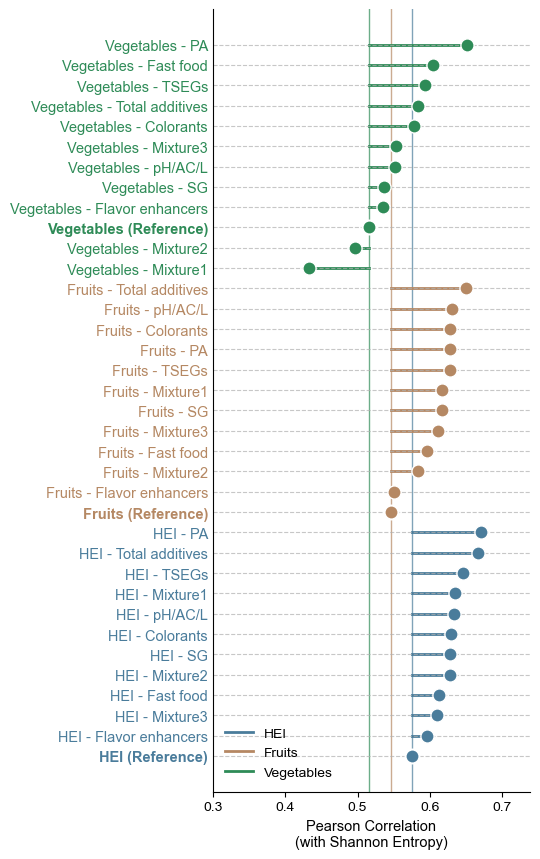

In [86]:
custom_refs = {
    "HEI": "LR_HEI",
    "fruits": "LR_fruits_fg_eaten",
    "vegetables": "LR_vegetables_fg_eaten",
}

custom_colors = {"HEI": "#4a7c9b", "fruits": "#b58863", "vegetables": "#2e8b57"}

fig, ax, corr_df = plot_shannon_lollipop_vertical(
    meta,
    cols_selected,
    reference_groups=custom_refs,
    ref_colors=custom_colors,
    figsize=(5.5, 8.7),
    xmin=0.3 if run_suffix == "adjustedBatch" else None,
)

plt.savefig(
    f"../figures/birdman/shannon_lollipop_{run_suffix}.png",
    dpi=300,
    bbox_inches="tight",
)

## Common Microbes

In [15]:
with open(f"./results_files/numerator_asvs_dict_{run_suffix}.pkl", "rb") as f:
    numerator_asvs_dict = pickle.load(f)

with open(f"./results_files/denominator_asvs_dict_{run_suffix}.pkl", "rb") as f:
    denominator_asvs_dict = pickle.load(f)

In [16]:
print("Numerator ASVs:", {i: len(numerator_asvs_dict[i]) for i in numerator_asvs_dict})

print(
    "Denominator ASVs:",
    {i: len(denominator_asvs_dict[i]) for i in denominator_asvs_dict},
)

Numerator ASVs: {'HEI': 58, 'HEI_minus_Mixture1': 61, 'HEI_minus_Mixture2': 53, 'HEI_minus_Mixture3': 56, 'HEI_minus_colorants': 51, 'HEI_minus_fast_food': 58, 'HEI_minus_flavor_enhancers': 61, 'HEI_minus_ph_regulators_anti_caking_leavening_agents': 59, 'HEI_minus_preservatives_antioxidants': 60, 'HEI_minus_sweeteners_glazing_agents': 54, 'HEI_minus_thickeners_stabilizers_emulsifiers_gelling_agents': 63, 'HEI_minus_total_additive_intake': 54, 'Mixture1': 10, 'Mixture2': 18, 'Mixture3': 21, 'colorants': 28, 'fast_food_fg_eaten': 31, 'flavor_enhancers': 14, 'fruits_fg_eaten': 60, 'fruits_minus_Mixture1': 57, 'fruits_minus_Mixture2': 50, 'fruits_minus_Mixture3': 63, 'fruits_minus_colorants': 51, 'fruits_minus_fast_food': 55, 'fruits_minus_flavor_enhancers': 52, 'fruits_minus_ph_regulators_anti_caking_leavening_agents': 51, 'fruits_minus_preservatives_antioxidants': 60, 'fruits_minus_sweeteners_glazing_agents': 54, 'fruits_minus_thickeners_stabilizers_emulsifiers_gelling_agents': 62, 'frui

In [17]:
def find_common_microbe(var1, var2, num_asv, denom_asv):
    var1_asv = set(num_asv[var1]).union(denom_asv[var1])
    var2_asv = set(num_asv[var2]).union(denom_asv[var2])

    return (
        len(var1_asv),
        len(var2_asv),
        len(list(var1_asv.intersection(var2_asv))),
    )

In [18]:
from itertools import combinations

var_pairs = list(combinations(denominator_asvs_dict.keys(), 2))

tuple_pair_data = {}
for pair in var_pairs:
    print(f"{pair[0]} - {pair[1]}")
    print(
        find_common_microbe(
            pair[0], pair[1], numerator_asvs_dict, denominator_asvs_dict
        )
    )
    tuple_pair_data[pair] = find_common_microbe(
        pair[0], pair[1], numerator_asvs_dict, denominator_asvs_dict
    )

HEI - HEI_minus_Mixture1
(100, 100, 70)
HEI - HEI_minus_Mixture2
(100, 100, 67)
HEI - HEI_minus_Mixture3
(100, 100, 59)
HEI - HEI_minus_colorants
(100, 100, 64)
HEI - HEI_minus_fast_food
(100, 100, 78)
HEI - HEI_minus_flavor_enhancers
(100, 100, 65)
HEI - HEI_minus_ph_regulators_anti_caking_leavening_agents
(100, 100, 69)
HEI - HEI_minus_preservatives_antioxidants
(100, 100, 70)
HEI - HEI_minus_sweeteners_glazing_agents
(100, 100, 58)
HEI - HEI_minus_thickeners_stabilizers_emulsifiers_gelling_agents
(100, 100, 68)
HEI - HEI_minus_total_additive_intake
(100, 100, 67)
HEI - Mixture1
(100, 47, 19)
HEI - Mixture2
(100, 56, 21)
HEI - Mixture3
(100, 56, 12)
HEI - colorants
(100, 72, 26)
HEI - fast_food_fg_eaten
(100, 100, 58)
HEI - flavor_enhancers
(100, 41, 11)
HEI - fruits_fg_eaten
(100, 100, 60)
HEI - fruits_minus_Mixture1
(100, 100, 60)
HEI - fruits_minus_Mixture2
(100, 100, 51)
HEI - fruits_minus_Mixture3
(100, 100, 49)
HEI - fruits_minus_colorants
(100, 100, 56)
HEI - fruits_minus_fast

~/miniconda3/envs/additives/lib/python3.12/site-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,
~/miniconda3/envs/additives/lib/python3.12/site-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,


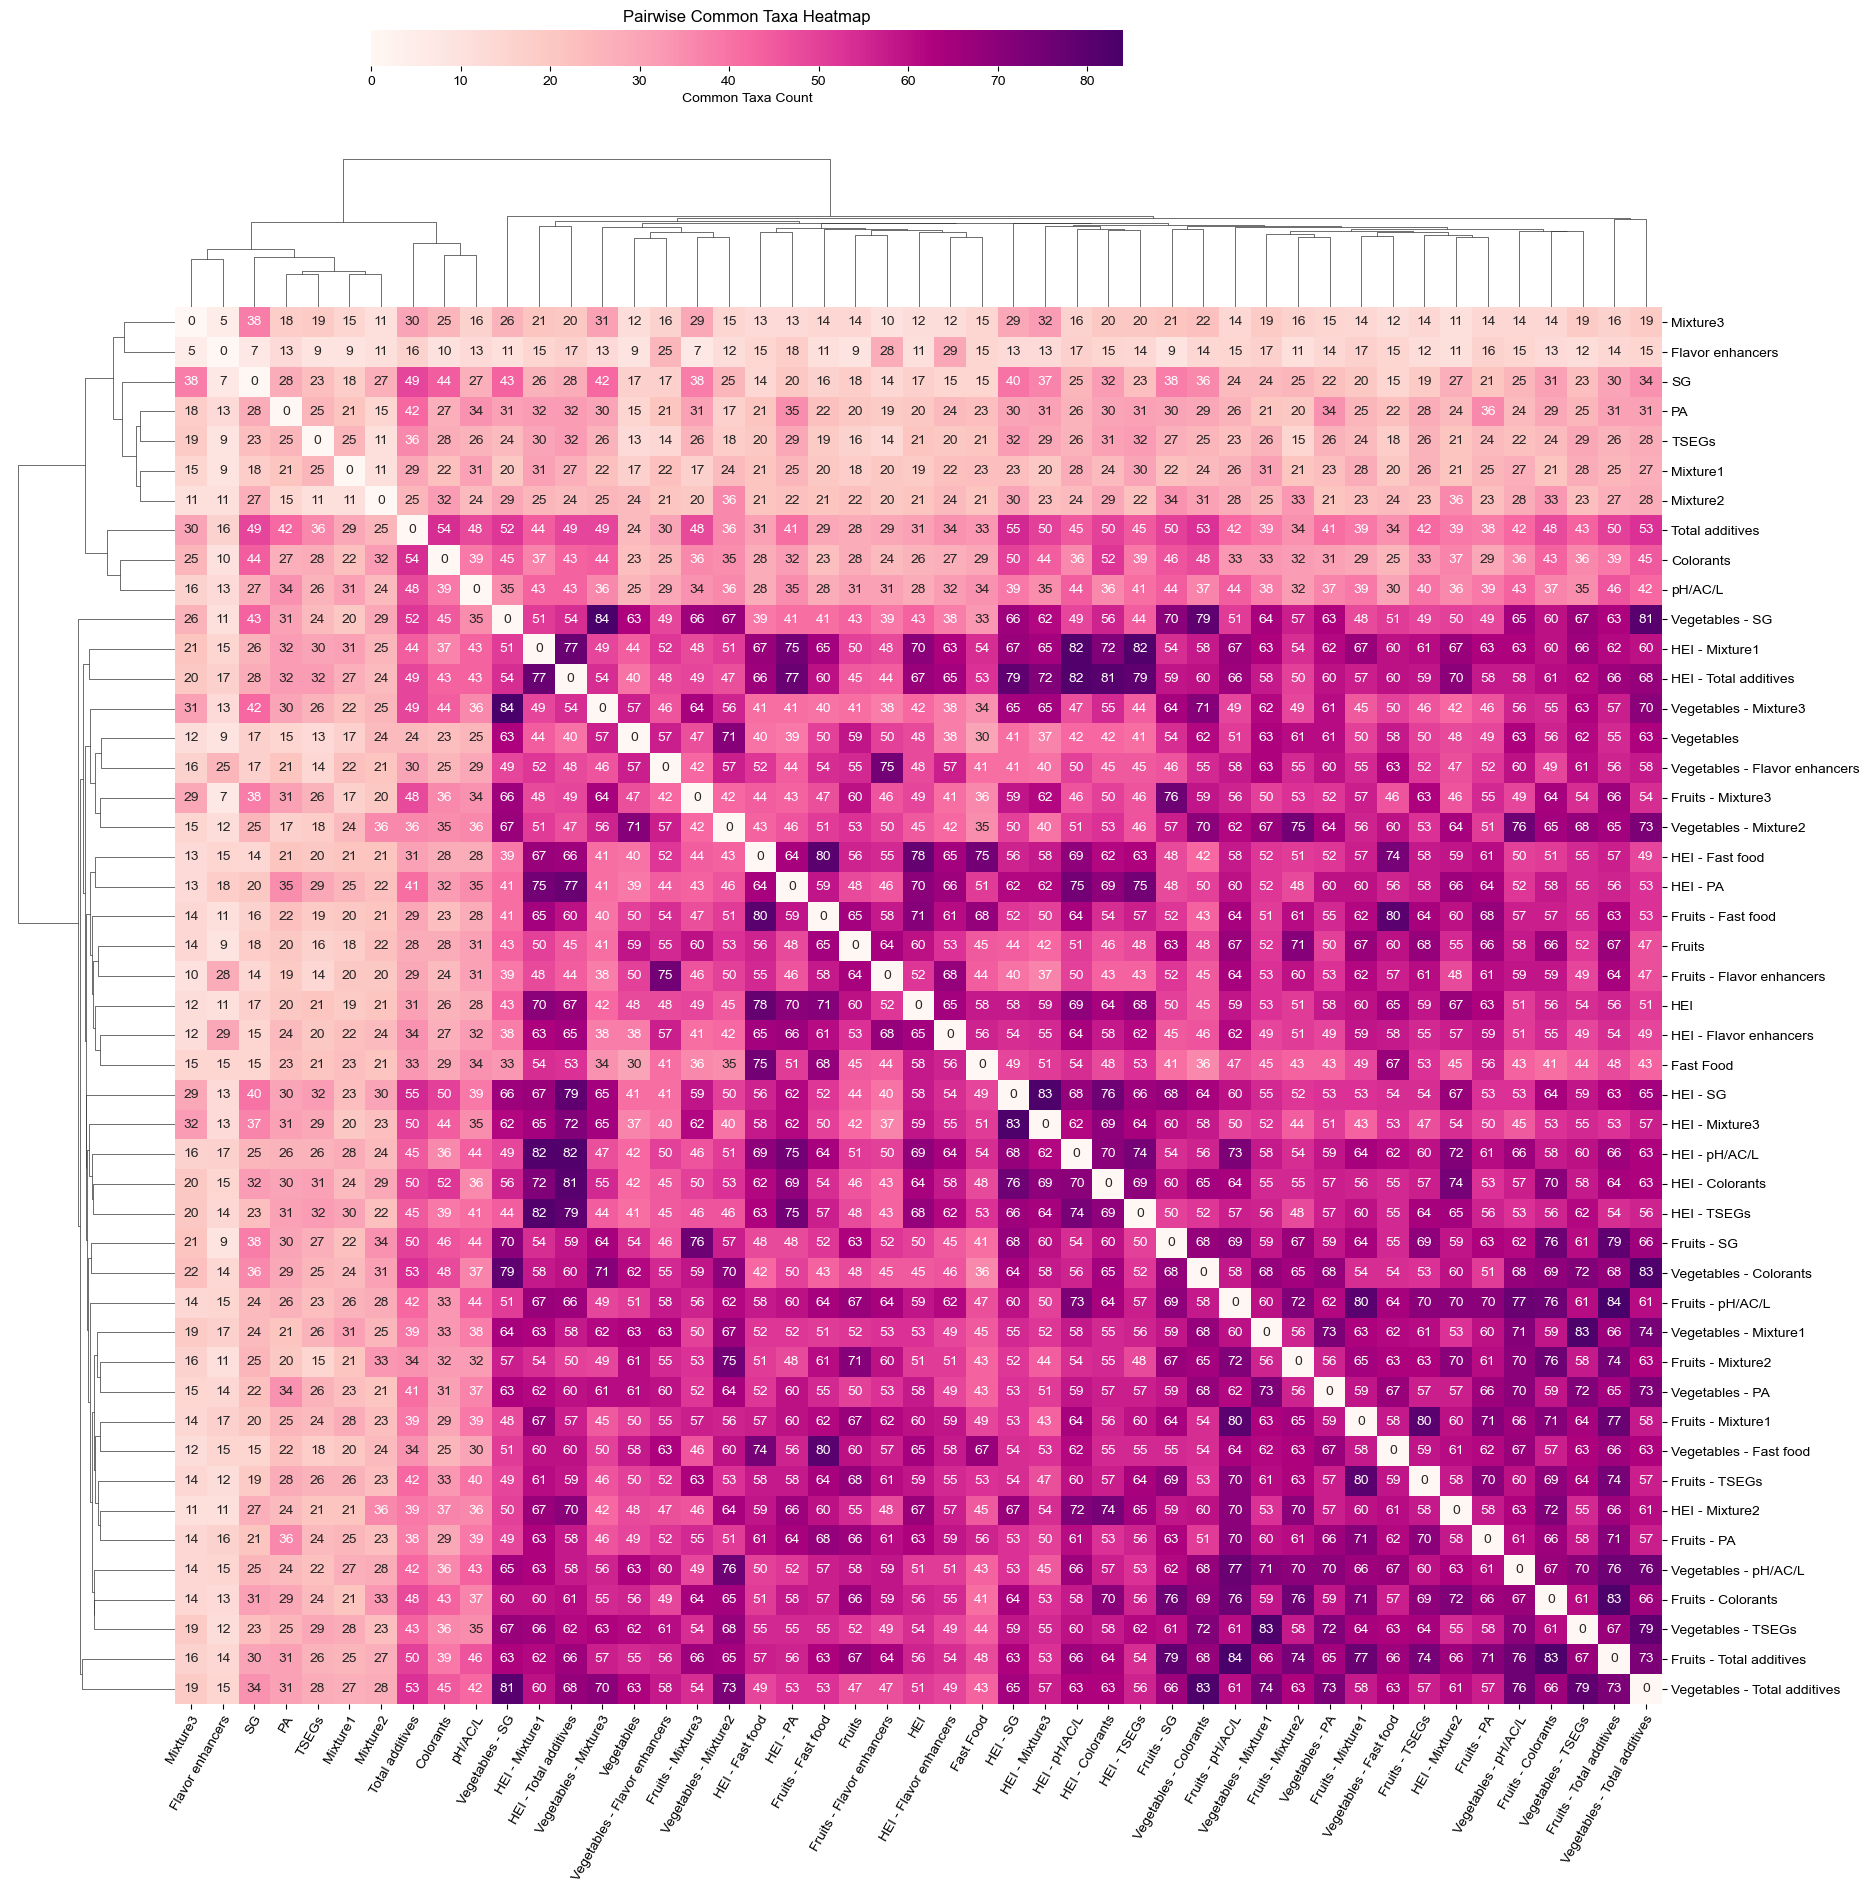

In [19]:
import matplotlib.transforms as mtrans


def plot_pairwise_heatmap(pair_data, figsize=(6, 6)):
    """
    Creates a heatmap of pairwise common taxa counts between additives.

    Parameters:
    -----------
    pair_data : dict
        Dictionary where keys are tuples of additive names (e.g., ("mean_antioxidants", "mean_daily_additives"))
        and values are tuples of the form (count1, count2, common_count).

    The function builds a symmetric matrix of the common taxa counts and plots it as a heatmap.
    """
    # Get the unique additive names
    additives = sorted({additive for pair in pair_data for additive in pair})

    # Initialize the matrix with zeros
    matrix = pd.DataFrame(0, index=additives, columns=additives)

    # Fill in the matrix with the common taxa counts for each pair
    for (add1, add2), counts in pair_data.items():
        common_count = counts[2]
        matrix.loc[add1, add2] = common_count
        matrix.loc[add2, add1] = common_count  # Ensure symmetry

    matrix.index = [
        process_string_pretty_vars(i.replace("mean_", "")) for i in matrix.index
    ]
    matrix.columns = [
        process_string_pretty_vars(i.replace("mean_", "")) for i in matrix.columns
    ]

    # Plot the heatmap
    # plt.figure(figsize=(5, 4))
    g = sns.clustermap(
        matrix,
        annot=True,
        fmt="d",
        cmap="RdPu",
        figsize=figsize,
        dendrogram_ratio=0.1,
        cbar_pos=(0.2, 1.04, 0.4, 0.02),
        cbar_kws={"orientation": "horizontal", "label": "Common Taxa Count"},
    )
    plt.setp(g.ax_heatmap.get_xticklabels(), rotation=60, ha="right")

    trans = mtrans.Affine2D().translate(10, 0)
    for t in g.ax_heatmap.get_xticklabels():
        t.set_transform(t.get_transform() + trans)

        plt.title("Pairwise Common Taxa Heatmap")
    return matrix


count_matrix = plot_pairwise_heatmap(tuple_pair_data, figsize=(18.8, 17.8))
plt.savefig(
    f"../figures/birdman/pairwise_common_taxa_heatmap_{run_suffix}.png",
    dpi=300,
    bbox_inches="tight",
)

In [20]:
# count_matrix.to_csv("count_matrix.csv")

## Prep for Effect Size Analysis

In [76]:
######### Based on Intersection #########
# additive_common_num_taxa = set(
#     numerator_asvs_dict["acidity_regulators_antioxidants"]
# ).intersection(set(numerator_asvs_dict["total_additives"]))

# additive_common_demon_taxa = set(
#     denominator_asvs_dict["acidity_regulators_antioxidants"]
# ).intersection(
#     set(denominator_asvs_dict["total_additives"]),
# )

# print("Common Numerator ASVs:", len(additive_common_num_taxa))
# print("Common Denominator ASVs:", len(additive_common_demon_taxa))
########################################################################

######### Based on Union
# additive_common_num_taxa = (
#     set(numerator_asvs_dict["Mixture1"])
#     .union(set(numerator_asvs_dict["Mixture2"]))
#     .union(set(numerator_asvs_dict["Mixture3"]))
# )

# additive_common_demon_taxa = (
#     set(denominator_asvs_dict["Mixture1"])
#     .union(set(denominator_asvs_dict["Mixture2"]))
#     .union(set(denominator_asvs_dict["Mixture3"]))
# )

# print("Common Numerator ASVs:", len(additive_common_num_taxa))
# print("Common Denominator ASVs:", len(additive_common_demon_taxa))

######### Based on Union (additive_vars)
additive_common_num_taxa = (
    set(numerator_asvs_dict["thickeners_stabilizers_emulsifiers_gelling_agents"])
    .union(set(numerator_asvs_dict["ph_regulators_anti_caking_leavening_agents"]))
    .union(set(numerator_asvs_dict["sweeteners_glazing_agents"]))
    # .union(set(numerator_asvs_dict["preservatives_antioxidants"]))
)

additive_common_demon_taxa = (
    set(denominator_asvs_dict["thickeners_stabilizers_emulsifiers_gelling_agents"])
    .union(set(denominator_asvs_dict["ph_regulators_anti_caking_leavening_agents"]))
    .union(set(denominator_asvs_dict["sweeteners_glazing_agents"]))
    # .union(set(denominator_asvs_dict["preservatives_antioxidants"]))
)

print("Common Numerator ASVs:", len(additive_common_num_taxa))
print("Common Denominator ASVs:", len(additive_common_demon_taxa))
print(len(additive_common_num_taxa.union(additive_common_demon_taxa)))

Common Numerator ASVs: 37
Common Denominator ASVs: 87
123


In [77]:
selected_vars = [
    "preservatives_antioxidants",
    "thickeners_stabilizers_emulsifiers_gelling_agents",
    "ph_regulators_anti_caking_leavening_agents",
    "sweeteners_glazing_agents",
    # "flavor_enhancers",
    # "colorants",
    # "Mixture1",
    # "Mixture2",
    # "HEI_minus_preservatives_antioxidants",
    # "HEI_minus_thickeners_stabilizers_emulsifiers_gelling_agents",
    # "HEI_minus_ph_regulators_anti_caking_leavening_agents",
    # "HEI_minus_sweeteners_glazing_agents",
    # "HEI_minus_flavor_enhancers",
    # "HEI_minus_colorants",
    # "HEI_minus_fast_food",
    "vegetables_minus_preservatives_antioxidants",
    "vegetables_minus_thickeners_stabilizers_emulsifiers_gelling_agents",
    "vegetables_minus_ph_regulators_anti_caking_leavening_agents",
    "vegetables_minus_sweeteners_glazing_agents",
    # "fast_food_fg_eaten",
    # "HEI",
    # "vegetables_fg_eaten",
    # "fruits_fg_eaten",
]

# selected_vars = additive_vars
# selected_vars = mixtures

for e, var in enumerate(sorted(selected_vars)):
    beta_var = pd.read_csv(
        f"{slurm_outputs_dir}/{var}/results/beta_var.tsv", sep="\t", index_col="Feature"
    )
    significant_feats = birdman_plot_single_var(beta_var, var, action="get_top_n", n=50)
    significant_feats["Taxon"] = significant_feats["Feature"].map(taxonomy_dict)

    significant_feats = significant_feats[
        significant_feats["Feature"].isin(
            additive_common_num_taxa.union(additive_common_demon_taxa)
        )
    ]
    print(var)
    vars_scp = ["Feature", var + "_mean"]
    if e == 0:
        common_significant_feats = significant_feats[vars_scp]
    else:
        common_significant_feats = common_significant_feats.merge(
            significant_feats[vars_scp], on="Feature", how="outer"
        )

print(common_significant_feats.shape)

ph_regulators_anti_caking_leavening_agents
preservatives_antioxidants
sweeteners_glazing_agents
thickeners_stabilizers_emulsifiers_gelling_agents
vegetables_minus_ph_regulators_anti_caking_leavening_agents
vegetables_minus_preservatives_antioxidants
vegetables_minus_sweeteners_glazing_agents
vegetables_minus_thickeners_stabilizers_emulsifiers_gelling_agents
(123, 9)


In [78]:
#### Option 1: Filter by absolute sum of effect sizes
# common_significant_feats_filtered = common_significant_feats.set_index("Feature")[
#     common_significant_feats.set_index("Feature").abs().sum(axis=1) > 0.25
# ].reset_index()

#### Option 2: Filter by presence of |effect size| > 0.25 across additive vars only
temp_common_significant_feats = common_significant_feats.copy().set_index("Feature")
temp_common_significant_feats = temp_common_significant_feats[
    [i for i in temp_common_significant_feats.columns if "minus" not in i]
]
temp_common_significant_feats = temp_common_significant_feats.abs().sum(axis=1) > 0.25
temp_common_significant_feats = temp_common_significant_feats[
    temp_common_significant_feats
].index

common_significant_feats_filtered = common_significant_feats[
    common_significant_feats["Feature"].isin(temp_common_significant_feats)
]

## Melt for plotting
common_significant_feats_melted = pd.melt(
    common_significant_feats_filtered.fillna(0),
    id_vars=["Feature"],
    value_vars=[
        col
        for col in common_significant_feats_filtered.columns
        if col.endswith("_mean")
    ],
    var_name="additive",
    value_name="effect_size",
)

common_significant_feats_melted["Taxon"] = common_significant_feats_melted[
    "Feature"
].map(taxonomy_dict)
common_significant_feats_melted["Feature"] = common_significant_feats_melted[
    "Feature"
].map(taxonID_shortName)

print(
    common_significant_feats_melted.shape,
    common_significant_feats_melted["Feature"].nunique(),
)
common_significant_feats_melted

(448, 4) 56


,Feature,additive,effect_size,Taxon
0,ASV_257 (g__Hominicoprocola),ph_regulators_anti_caking_leavening_agents_mean,-0.165323,d__Bacteria; p__Bacillota_A_368345; c__Clostri...
1,ASV_89 (g__Alistipes_A_871400),ph_regulators_anti_caking_leavening_agents_mean,0.091498,d__Bacteria; p__Bacteroidota; c__Bacteroidia; ...
2,ASV_161 (g__Blautia_A_141781),ph_regulators_anti_caking_leavening_agents_mean,0.000000,d__Bacteria; p__Bacillota_A_368345; c__Clostri...
3,ASV_242 (g__Methanobrevibacter_A),ph_regulators_anti_caking_leavening_agents_mean,0.000000,d__Archaea; p__Methanobacteriota_A_1229; c__Me...
4,ASV_51 (g__Dysosmobacter),ph_regulators_anti_caking_leavening_agents_mean,0.000000,d__Bacteria; p__Bacillota_A_368345; c__Clostri...
...,...,...,...,...
443,ASV_49 (g__Blautia_A_141781),vegetables_minus_thickeners_stabilizers_emulsi...,0.000000,d__Bacteria; p__Bacillota_A_368345; c__Clostri...
444,ASV_177 (g__Dysosmobacter),vegetables_minus_thickeners_stabilizers_emulsi...,0.000000,d__Bacteria; p__Bacillota_A_368345; c__Clostri...
445,ASV_388 (f__Lachnospiraceae),vegetables_minus_thickeners_stabilizers_emulsi...,0.236186,d__Bacteria; p__Bacillota_A_368345; c__Clostri...
446,ASV_326 (g__Onthomonas),vegetables_minus_thickeners_stabilizers_emulsi...,0.000000,d__Bacteria; p__Bacillota_A_368345; c__Clostri...


In [24]:
common_significant_feats_melted.to_csv(
    f"../outputs/supplementary_files/differential_taxa_effect_size_{run_suffix}.csv",
    index=False,
)

In [25]:
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list
from scipy.spatial.distance import pdist


def plot_scatter_heatmap(
    data,
    figsize=(5, 12),
    center=0,
    clip_quantiles=(0.05, 0.95),
    clip_abs_max=None,
):
    """
    Create a scatter-style heatmap with divergent colors (red-white-purple) and clustered features.

    Parameters:
    -----------
    data : pandas.DataFrame
        DataFrame with columns: 'Feature', 'additive', 'effect_size'
    figsize : tuple
        Figure dimensions as (width, height)
    center : float
        Center point for the divergent colormap (default=0). (Kept for API compatibility.)
    clip_quantiles : tuple(float, float)
        Quantiles used to set robust symmetric color limits (default=(0.05, 0.95)).
        Ignored if clip_abs_max is provided.
    clip_abs_max : float or None
        If provided, uses this fixed symmetric color limit [-clip_abs_max, clip_abs_max]
        for both point colors and colorbar.

    Returns:
    --------
    fig, ax : matplotlib figure and axis objects
    """
    # Create figure and axis
    fig, ax = plt.subplots(figsize=figsize)

    cmap = plt.colormaps["seismic"]

    # Get unique categories and additives
    features = data["Feature"].unique()
    additives = data["additive"].unique()

    # Create a pivot table for clustering
    pivot_data = data.pivot(index="Feature", columns="additive", values="effect_size")

    # Perform hierarchical clustering on features
    dist_matrix = pdist(pivot_data.fillna(0))
    linkage_matrix = linkage(dist_matrix, method="ward")
    feature_order = leaves_list(linkage_matrix)

    # Reorder features based on clustering
    ordered_features = pivot_data.index[feature_order]

    # Create mapping of additives to x-positions
    additive_to_pos = {additive: i for i, additive in enumerate(additives)}

    # Robust symmetric color scaling
    if clip_abs_max is not None:
        abs_max = float(clip_abs_max)
    else:
        q_low, q_high = clip_quantiles
        lower_q, upper_q = data["effect_size"].quantile([q_low, q_high])
        abs_max = max(abs(lower_q), abs(upper_q))

    # Avoid division by zero if everything is 0
    if abs_max == 0 or np.isnan(abs_max):
        abs_max = 1.0

    # Function to normalize effect sizes to [0, 1] for divergent colormap, with clipping
    def normalize_divergent(value):
        value = np.clip(value, -abs_max, abs_max)
        return value / (2 * abs_max) + 0.5  # Map [-abs_max, abs_max] to [0, 1]

    # Iterate over additives
    for additive in additives:
        # Select data for the given additive
        mask = data["additive"] == additive
        d = data[mask].copy()

        # Sort according to clustering order
        d["Feature"] = pd.Categorical(
            d["Feature"], categories=ordered_features, ordered=True
        )
        d = d.sort_values("Feature")

        # Get x and y values
        x = [additive_to_pos[additive]] * len(d)
        y = d["Feature"]

        # Generate colors based on normalized (and clipped) effect sizes
        colors = cmap([normalize_divergent(val) for val in d["effect_size"]])

        # Plot the markers
        ax.scatter(x, y, color=colors, s=80)

    # Customize the plot
    ax.set_frame_on(False)
    ax.grid(alpha=0.4)
    ax.set_axisbelow(True)

    # Set and format ticks
    ax.set_xticks(np.arange(len(additives)))
    ax.set_xticklabels(
        [
            process_string_pretty_vars(
                a.replace("mean_", "").replace("_mean", ""), newLineSep=10
            )
            for a in additives
        ],
        rotation=45,
        rotation_mode="anchor",
        ha="right",
    )

    # Set y-axis labels in clustered order
    ax.set_yticks(np.arange(len(ordered_features)))
    ax.set_yticklabels(ordered_features)

    # Remove tick marks and set color
    ax.tick_params(size=0, colors="0.3")

    # Add colorbar using the same clipped limits
    sm = plt.cm.ScalarMappable(
        cmap=cmap, norm=plt.Normalize(vmin=-abs_max, vmax=abs_max)
    )
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, fraction=0.05, shrink=0.3, pad=0.1)
    cbar.set_label("Mean Effect Size (BIRDMan)", color="0.3")
    cbar.ax.tick_params(colors="0.3")

    # Adjust y-axis limits
    y_shrunk = 0.75
    y_lower, y_upper = ax.get_ylim()
    ax.set_ylim(y_lower + y_shrunk, y_upper - y_shrunk)

    # Adjust layout
    plt.tight_layout()

    return fig, ax

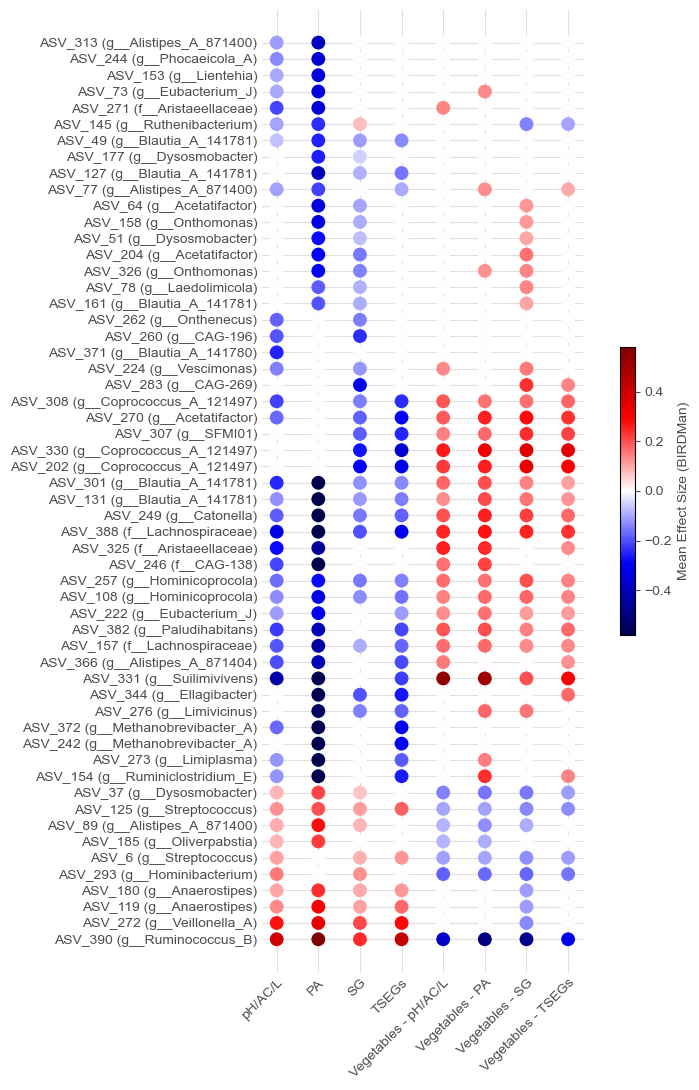

In [26]:
fig, ax = plot_scatter_heatmap(
    common_significant_feats_melted,
    figsize=(7, 11),
    clip_quantiles=(
        0.02,
        0.98,
    ),  # try (0.1, 0.9) for more color contrast, or (0, 1) for no clipping
    # clip_abs_max=0.3,  # uncomment to use a fixed limit instead
)

plt.savefig(
    f"../figures/birdman/differential_taxa_effect_size_scatter_heatmap_{run_suffix}.png",
    bbox_inches="tight",
    dpi=300,
)

In [27]:
common_significant_feats_melted[
    common_significant_feats_melted["Feature"].str.contains("ASV_388")
]

,Feature,additive,effect_size,Taxon
53,ASV_388 (f__Lachnospiraceae),ph_regulators_anti_caking_leavening_agents_mean,-0.334440,d__Bacteria; p__Bacillota_A_368345; c__Clostri...
109,ASV_388 (f__Lachnospiraceae),preservatives_antioxidants_mean,-0.604644,d__Bacteria; p__Bacillota_A_368345; c__Clostri...
165,ASV_388 (f__Lachnospiraceae),sweeteners_glazing_agents_mean,-0.196937,d__Bacteria; p__Bacillota_A_368345; c__Clostri...
221,ASV_388 (f__Lachnospiraceae),thickeners_stabilizers_emulsifiers_gelling_age...,-0.314219,d__Bacteria; p__Bacillota_A_368345; c__Clostri...
277,ASV_388 (f__Lachnospiraceae),vegetables_minus_ph_regulators_anti_caking_lea...,0.249131,d__Bacteria; p__Bacillota_A_368345; c__Clostri...
333,ASV_388 (f__Lachnospiraceae),vegetables_minus_preservatives_antioxidants_mean,0.271503,d__Bacteria; p__Bacillota_A_368345; c__Clostri...
389,ASV_388 (f__Lachnospiraceae),vegetables_minus_sweeteners_glazing_agents_mean,0.251055,d__Bacteria; p__Bacillota_A_368345; c__Clostri...
445,ASV_388 (f__Lachnospiraceae),vegetables_minus_thickeners_stabilizers_emulsi...,0.236186,d__Bacteria; p__Bacillota_A_368345; c__Clostri...


In [28]:
t = (
    common_significant_feats_melted[
        (common_significant_feats_melted["effect_size"].abs() > 0)
        # & ~(common_significant_feats_melted["additive"].str.contains("minus"))
    ]["Feature"]
    .value_counts()
    .index.tolist()
)

In [29]:
def get_asv_iqr(df, asv_list):
    # Filter for specified ASVs
    asv_data = df[df["Feature"].str.contains("|".join(asv_list))]

    # Separate HEI-minus and additive-only
    hei_minus = asv_data[asv_data["additive"].str.contains("HEI_minus")]["effect_size"]
    additive_only = asv_data[~asv_data["additive"].str.contains("HEI_minus")][
        "effect_size"
    ]
    additive_only = additive_only[additive_only < 0]  # Only negative values

    # Calculate stats
    hei_stats = hei_minus.describe(percentiles=[0.25, 0.5, 0.75])
    add_stats = additive_only.describe(percentiles=[0.25, 0.5, 0.75])

    print(
        f"HEI-minus: Median = {hei_stats['50%']:.3f}, IQR = {hei_stats['25%']:.3f} to {hei_stats['75%']:.3f}"
    )
    print(
        f"Additive-only: Median = {add_stats['50%']:.3f}, IQR = {add_stats['25%']:.3f} to {add_stats['75%']:.3f}"
    )

    return None  # hei_stats, add_stats


get_asv_iqr(
    common_significant_feats_melted,
    # ["ASV_388", "ASV_330", "ASV_202", "ASV_222", "ASV_301", "ASV_336"],
    [x.split(" (")[0] for x in t],
)

HEI-minus: Median = nan, IQR = nan to nan
Additive-only: Median = -0.181, IQR = -0.300 to -0.128


## Mirror Barplot

In [67]:
def create_mirror_barplot(
    df,
    variable_col="variable_short",
    numerator_col="num_numerator_asvs",
    denominator_col="num_denominator_asvs",
    ax=None,
    title="Numerator vs Denominator Counts",
    bar_alpha=0.3,
    text_size=8,
    panel_text="E",
    panel_pos=(-1, 1.02),
    figsize=(5, 7),
):
    """
    Create a mirror barplot showing numerator and denominator counts.

    Parameters:
    -----------
    df : pandas DataFrame
        Input dataframe containing the data
    variable_col : str
        Column name containing variable names
    numerator_col : str
        Column name containing numerator counts
    denominator_col : str
        Column name containing denominator counts
    figsize : tuple
        Figure size as (width, height)
    title : str
        Title of the plot
    bar_alpha : float
        Transparency of the bars (0-1)
    text_size : int
        Size of the text labels
    panel_text : str
        Text to display at the top left of the panel

    Returns:
    --------
    fig, ax : matplotlib figure and axis objects
    """
    df = df.copy()
    # df = df.sort_values(['num_feats', 'num_numerator_asvs', 'num_denominator_asvs', variable_col], ascending=[True, True, True, True])
    df = df.sort_values(["num_numerator_asvs", "num_denominator_asvs", variable_col])

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)

    # Create both barplots
    ax.barh(
        df[variable_col],
        df[numerator_col],
        height=0.8,
        color="blue",
        alpha=bar_alpha,
        label="Numerator",
    )
    ax.barh(
        df[variable_col],
        -df[denominator_col],
        height=0.8,
        color="darkorange",
        alpha=bar_alpha,
    )

    # Add vertical dashed grid lines
    ax.xaxis.grid(
        True, linestyle="dotted", which="both", color="gray", alpha=0.7, zorder=2
    )

    # Remove axis labels and spines
    ax.set_xticklabels([str(int(abs(x))) for x in ax.get_xticks()])
    ax.set_yticks([])
    ax.spines[
        [
            "right",
            "top",
            "left",
        ]
    ].set_visible(False)

    # Put variable names in the center
    for i, var_name in enumerate(df[variable_col]):
        ax.text(
            0,
            i,
            var_name,
            ha="center",
            va="center",
            fontweight="bold",
            fontsize=text_size,
            alpha=0.8,
        )

    # Add labels for the sides
    max_value = max(df[numerator_col].max(), df[denominator_col].max())
    ax.text(
        -max_value * 0.8,
        1,
        "Denominator\nASVs",
        color="darkorange",
        ha="center",
        va="center",
        weight="bold",
        fontsize=text_size + 2,
    )
    ax.text(
        max_value * 0.7,
        1,
        "Numerator\nASVs",
        color="blue",
        ha="center",
        va="center",
        weight="bold",
        fontsize=text_size + 2,
    )

    # Add panel text at top left
    ax.text(
        panel_pos[0],
        panel_pos[1],
        panel_text,
        transform=ax.transAxes,
        fontsize=16,
        fontweight="bold",
        va="top",
        ha="left",
    )

    # Set title
    # ax.set_title(title, pad=10, weight='bold')

    # Adjust layout
    return ax

### Load Counts stats data from Differential Abundance Results

In [68]:
diffAbun_res_df = pd.read_csv(
    f"./results_files/differential_abundance_mirrorplot_stats_{run_suffix}.csv",
    index_col=0,
)

In [69]:
print(
    diffAbun_res_df.sort_values("num_feats", ascending=False)["variable"][
        :15
    ].values.tolist()
)

diffAbun_res_df.sort_values(
    ["num_feats", "variable"], ascending=[False, False], inplace=True
)
diffAbun_res_df["variable_short"] = diffAbun_res_df["variable"].apply(
    process_string_pretty_vars
)

['HEI', 'vegetables_minus_Mixture1', 'HEI_minus_Mixture1', 'fruits_minus_flavor_enhancers', 'fruits_minus_ph_regulators_anti_caking_leavening_agents', 'fruits_minus_preservatives_antioxidants', 'fruits_minus_sweeteners_glazing_agents', 'fruits_minus_thickeners_stabilizers_emulsifiers_gelling_agents', 'fruits_minus_total_additive_intake', 'vegetables_fg_eaten', 'vegetables_minus_Mixture2', 'fruits_minus_Mixture3', 'vegetables_minus_Mixture3', 'vegetables_minus_colorants', 'vegetables_minus_fast_food']


/var/folders/kl/wv2_2q3n4z3d2bxtztx97rgc0000gn/T/ipykernel_56625/1213946451.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([str(int(abs(x))) for x in ax.get_xticks()])


Text(0.5, 0, 'Number of Differentially Abundant Taxa\n(out of 100)')

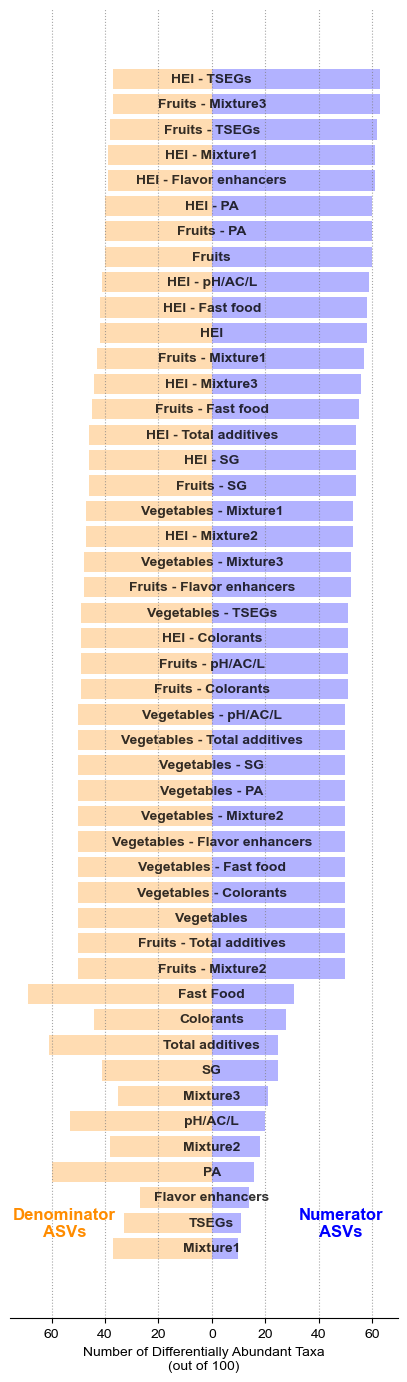

In [70]:
fig, ax = plt.subplots(figsize=(5, 17))
mirror_plot_data = diffAbun_res_df[diffAbun_res_df["num_feats"] > 10]
# mirror_plot_data = mirror_plot_data[
#     ~mirror_plot_data["variable"].isin(["vegetables_fruits", "oils_fats_nuts"])
# ]

mirror_plot_data = mirror_plot_data[
    # ~(mirror_plot_data["variable"].str.contains("vegetables"))
    # & ~(mirror_plot_data["variable"].str.contains("fruits"))
    ~(mirror_plot_data["variable"].str.contains("oils"))
    & ~(mirror_plot_data["variable"].str.contains("zscore"))
]

create_mirror_barplot(
    mirror_plot_data,
    ax=ax,
    # title='Number of Differentially Abundant ASVs',
    text_size=10,
    panel_text=None,
    panel_pos=(-0.1, 1),
)
ax.set_xlabel("Number of Differentially Abundant Taxa\n(out of 100)")

# plt.savefig(
#     f"../figures/birdman/differential_taxa_counts_{run_suffix}.png",
#     bbox_inches="tight",
#     dpi=300,
# )

/var/folders/kl/wv2_2q3n4z3d2bxtztx97rgc0000gn/T/ipykernel_56625/1213946451.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([str(int(abs(x))) for x in ax.get_xticks()])


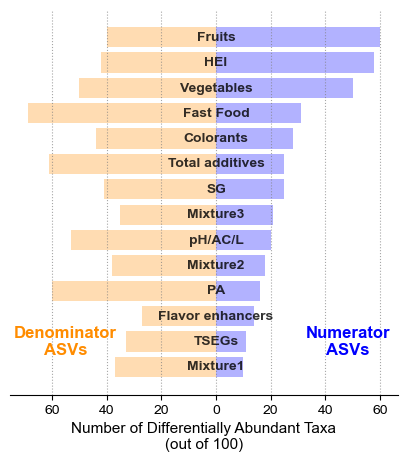

In [71]:
fig, ax = plt.subplots(figsize=(5, 5))
mirror_plot_data = diffAbun_res_df[diffAbun_res_df["num_feats"] > 10]
# mirror_plot_data = mirror_plot_data[
#     ~mirror_plot_data["variable"].isin(["vegetables_fruits", "oils_fats_nuts"])
# ]

mirror_plot_data = mirror_plot_data[~mirror_plot_data["variable"].str.contains("minus")]

create_mirror_barplot(
    mirror_plot_data,
    ax=ax,
    # title='Number of Differentially Abundant ASVs',
    text_size=10,
    panel_text=None,
    panel_pos=(-0.1, 1),
)
ax.set_xlabel("Number of Differentially Abundant Taxa\n(out of 100)", fontsize=11)

plt.savefig(
    f"../figures/birdman/differential_taxa_counts_{run_suffix}.png",
    bbox_inches="tight",
    dpi=300,
)

In [72]:
mirror_plot_data

,variable,num_feats,corr,num_numerator_asvs,num_denominator_asvs,variable_short
35,vegetables_fg_eaten,100,0.358113,50,50,Vegetables
18,fruits_fg_eaten,100,0.343941,60,40,Fruits
16,fast_food_fg_eaten,100,0.380297,31,69,Fast Food
0,HEI,100,0.430200,58,42,HEI
34,total_additive_intake,86,0.231017,25,61,Total additives
31,preservatives_antioxidants,76,0.246104,16,60,PA
30,ph_regulators_anti_caking_leavening_agents,73,0.248560,20,53,pH/AC/L
15,colorants,72,0.250754,28,44,Colorants
32,sweeteners_glazing_agents,66,0.183991,25,41,SG
14,Mixture3,56,0.320502,21,35,Mixture3


/var/folders/kl/wv2_2q3n4z3d2bxtztx97rgc0000gn/T/ipykernel_56625/1213946451.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([str(int(abs(x))) for x in ax.get_xticks()])


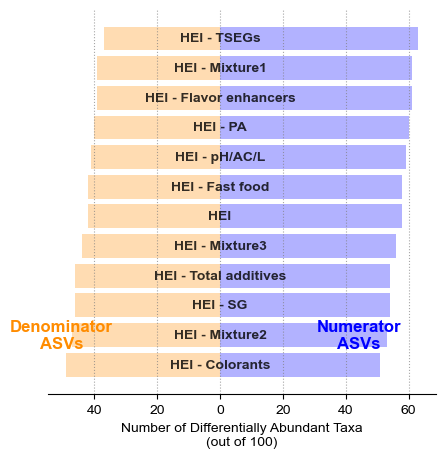

In [73]:
fig, ax = plt.subplots(figsize=(5, 5))
mirror_plot_data = diffAbun_res_df[diffAbun_res_df["num_feats"] > 10]
mirror_plot_data = mirror_plot_data[mirror_plot_data["variable"].str.startswith("HEI")]

create_mirror_barplot(
    mirror_plot_data,
    ax=ax,
    # title='Number of Differentially Abundant ASVs',
    text_size=10,
    panel_text=None,
    panel_pos=(-0.1, 1),
)
ax.set_xlabel("Number of Differentially Abundant Taxa\n(out of 100)")

plt.savefig(
    f"../figures/birdman/differential_taxa_counts_HEI_minus_{run_suffix}.png",
    bbox_inches="tight",
    dpi=300,
)

In [74]:
mirror_plot_data.drop(["corr", "num_feats", "variable"], axis=1)

,num_numerator_asvs,num_denominator_asvs,variable_short
11,54,46,HEI - Total additives
10,63,37,HEI - TSEGs
9,54,46,HEI - SG
8,60,40,HEI - PA
7,59,41,HEI - pH/AC/L
6,61,39,HEI - Flavor enhancers
5,58,42,HEI - Fast food
4,51,49,HEI - Colorants
3,56,44,HEI - Mixture3
2,53,47,HEI - Mixture2


## Log ratio scatter plots

In [37]:
import scipy.stats as stats


def plot_log_ratio_scatter(
    lr,
    var1,
    var2,
    xlabel=None,
    ylabel=None,
    ax=None,
    textpos=[0.35, 0.95],
    cmap="BuGn",
    show_legend=True,
):
    # Set up the figure and axis if not provided
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 4))
    else:
        fig = ax.figure

    ylabel = var1 if ylabel is None else ylabel
    # Create scatter plot
    points = ax.scatter(lr[var2], lr[var1], c=lr["shannon_entropy"], s=10, cmap=cmap)

    if show_legend:
        cbar = fig.colorbar(points, ax=ax, fraction=0.03, pad=0.04)
        cbar.set_label("Shannon Entropy")

    # Add regression line
    # Reduce line color boldness using a more transparent gray color for the regression line
    sns.regplot(
        data=lr,
        x=var2,
        y=var1,
        scatter=False,
        color=(0.1, 0.1, 0.1, 0.1),  # RGBA tuple, last value is alpha for transparency
        ax=ax,
        label="_nolegend_",
    )

    # Calculate Pearson correlation
    corr, p_value = stats.pearsonr(lr[var2], lr[var1])

    print(corr, p_value)

    # Annotate the plot with the R value in italics
    ax.text(
        textpos[0],
        textpos[1],
        f"$r = {corr:.2f}$",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=10,
        bbox=dict(facecolor="white", alpha=0.5),
    )

    if not show_legend:
        legend = ax.get_legend()
        if legend is not None:
            legend.remove()

    # ax.set_xlabel(f"Log Ratio$_\mathrm{{{log_ratio_label}}}$")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    # Remove top and right spines
    sns.despine(ax=ax)

    return fig, ax

0.38418597703282537 5.095888729898219e-35
-0.3521323434501915 2.5606267636543106e-29
-0.19903337201419172 5.25214081176841e-10


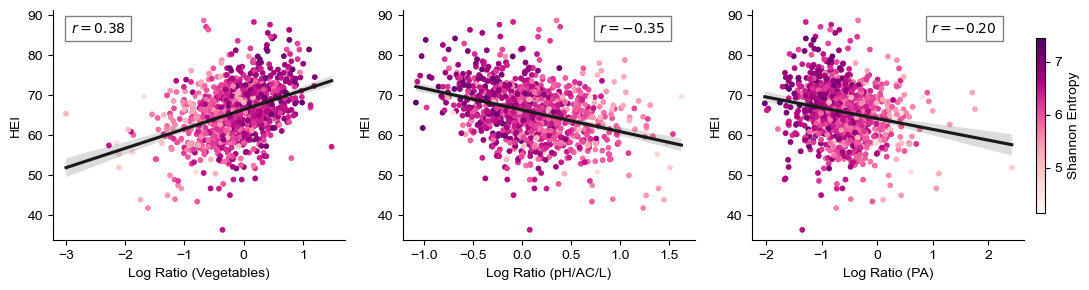

In [48]:
fig, ax = plt.subplots(ncols=3, nrows=1, figsize=(11, 3))

plot_log_ratio_scatter(
    meta,
    "HEI",
    "LR_vegetables_fg_eaten",
    xlabel=process_string_pretty_vars("LR_vegetables_fg_eaten"),
    ylabel=process_string_pretty_vars("HEI"),
    ax=ax[0],
    textpos=(0.25, 0.95),
    cmap="RdPu",
    show_legend=False,
)

plot_log_ratio_scatter(
    meta,
    "HEI",
    "LR_ph_regulators_anti_caking_leavening_agents",
    xlabel=process_string_pretty_vars(
        "LR_ph_regulators_anti_caking_leavening_agents", newLineSep=6
    ),
    ylabel=process_string_pretty_vars("HEI"),
    ax=ax[1],
    textpos=(0.9, 0.95),
    cmap="RdPu",
    show_legend=False,
)

plot_log_ratio_scatter(
    meta,
    "HEI",
    "LR_preservatives_antioxidants",
    xlabel=process_string_pretty_vars("LR_preservatives_antioxidants", newLineSep=5),
    ylabel=process_string_pretty_vars("HEI"),
    ax=ax[2],
    textpos=(0.9, 0.95),
    cmap="RdPu",
    show_legend=True,
)

# plot_log_ratio_scatter(
#     meta,
#     "daily_HEI",
#     "LR_sweeteners_glazing_agents",
#     xlabel=process_string_pretty_vars("LR_sweeteners_glazing_agents", newLineSep=5),
#     ylabel=process_string_pretty_vars("daily_HEI"),
#     ax=ax[3],
#     textpos=(0.9, 0.95),
#     cmap="RdPu",
#     show_legend=True,
# )

plt.tight_layout()
plt.savefig(
    f"../figures/birdman/scatter_plots_logratios_{run_suffix}.png",
    bbox_inches="tight",
    dpi=300,
)

0.019712100353978777 0.5424818641995042


(<Figure size 400x200 with 2 Axes>,
 <Axes: xlabel='Log Ratio (SG)', ylabel='Total Sugars (g/day)'>)

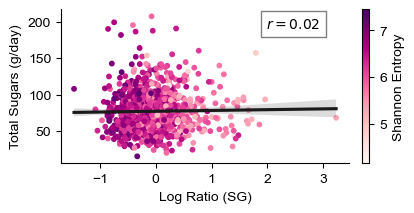

In [54]:
fig, ax = plt.subplots(figsize=(4, 2))

var = "LR_sweeteners_glazing_agents"
plot_log_ratio_scatter(
    meta,
    "sugar_eaten",
    var,
    ylabel="Total Sugars (g/day)",
    xlabel=process_string_pretty_vars(var, newLineSep=2),
    textpos=(0.9, 0.95),
    cmap="RdPu",
    show_legend=True,
    ax=ax,
)

In [40]:
print(meta.corr(numeric_only=True)["LR_preservatives_antioxidants"].sort_values()[:10])
meta.corr(numeric_only=True)["LR_preservatives_antioxidants"].sort_values()[-20:]

LR_HEI_minus_thickeners_stabilizers_emulsifiers_gelling_agents      -0.622833
LR_HEI_minus_preservatives_antioxidants                             -0.619528
LR_vegetables_minus_preservatives_antioxidants                      -0.618534
LR_fruits_minus_Mixture3                                            -0.597295
LR_HEI_minus_total_additive_intake                                  -0.594399
LR_HEI_minus_Mixture1                                               -0.579621
LR_fruits_minus_preservatives_antioxidants                          -0.573006
LR_fruits_minus_Mixture1                                            -0.569386
LR_fruits_minus_thickeners_stabilizers_emulsifiers_gelling_agents   -0.567710
LR_HEI_minus_colorants                                              -0.565446
Name: LR_preservatives_antioxidants, dtype: float64


Mixture1_zscore                                         0.161735
Mixture1                                                0.161735
fast_food_fg_eaten                                      0.178447
fast_food_zscore                                        0.178447
total_additive_intake                                   0.182402
total_additive_intake_zscore                            0.182402
CV_oils_nuts_fg_eaten                                   0.190821
preservatives_antioxidants                              0.225859
preservatives_antioxidants_zscore                       0.225859
LR_Mixture2                                             0.267297
LR_flavor_enhancers                                     0.298588
LR_Mixture1                                             0.310694
LR_fast_food_fg_eaten                                   0.403532
LR_Mixture3                                             0.462934
LR_colorants                                            0.503881
LR_ph_regulators_anti_cak